<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №3
## по курсу «Технологии машинного обучения»

### Тема: Подготовка обучающей и тестовой выборки, кросс-валидация и подбор гиперпараметров на примере метода ближайших соседей

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Описание задания

**Цель работы:** изучение способов подготовки выборки и подбора гиперпараметров на примере метода ближайших соседей.

**Задание:**
1. Выбрать набор данных для решения задачи классификации или регрессии.
2. В случае необходимости провести удаление или заполнение пропусков и кодирование категориальных признаков.
3. С использованием метода train_test_split разделить выборку на обучающую и тестовую.
4. Обучить модель ближайших соседей для произвольно заданного гиперпараметра K. Оценить качество модели с помощью подходящих для задачи метрик.
5. Произвести подбор гиперпараметра K с использованием GridSearchCV и RandomizedSearchCV и кросс-валидации, оценить качество оптимальной модели. Использовать не менее двух стратегий кросс-валидации.
6. Сравнить метрики качества исходной и оптимальной моделей.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, ShuffleSplit
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False

# палитра как в прошлых лабах
BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"


## 2. Набор данных

Используется тот же финансовый датасет, что и во второй лабораторной, — **Loan Prediction Problem Dataset** (заявки на кредит, https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset). Задача — **бинарная классификация**: по анкете клиента предсказать, одобрят ли ему кредит (`Loan_Status`: Y / N).

614 заявок, 11 признаков + целевой признак. В данных есть пропуски и категориальные признаки, поэтому сначала повторяем предобработку из ЛР2.


In [2]:
df = pd.read_csv("loan_prediction.csv")
print("Размер:", df.shape)
df.head()


Размер: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Распределение целевого признака:")
print(df["Loan_Status"].value_counts())
print()
print((df["Loan_Status"].value_counts(normalize=True) * 100).round(1))


Распределение целевого признака:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan_Status
Y    68.7
N    31.3
Name: proportion, dtype: float64


Классы несбалансированы: одобренных заявок примерно 69%, отказов — 31%. Поэтому кроме accuracy будем смотреть precision, recall, F1 и ROC-AUC, а при разбиении сохранять пропорции классов (`stratify`).

## 3. Предобработка данных (пропуски и категориальные признаки)


In [4]:
data = df.drop(columns=["Loan_ID"])

# пропуски: LoanAmount - медианой, остальное - модой (как в ЛР2)
data[["LoanAmount"]] = SimpleImputer(strategy="median").fit_transform(data[["LoanAmount"]])
mode_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Loan_Amount_Term", "Credit_History"]
data[mode_cols] = SimpleImputer(strategy="most_frequent").fit_transform(data[mode_cols])

# кодирование категориальных признаков
for col in ["Gender", "Married", "Education", "Self_Employed", "Loan_Status"]:
    data[col] = LabelEncoder().fit_transform(data[col])
data["Dependents"] = OrdinalEncoder(categories=[["0", "1", "2", "3+"]]).fit_transform(data[["Dependents"]])
data = pd.get_dummies(data, columns=["Property_Area"], prefix="Area", dtype=int)
data = data.astype(float)

print("Пропусков:", data.isnull().sum().sum())
data.head()


Пропусков: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,1.0,0.0,0.0,0.0,0.0,5849.0,0.0,128.0,360.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,1.0,0.0,0.0,4583.0,1508.0,128.0,360.0,1.0,0.0,1.0,0.0,0.0
2,1.0,1.0,0.0,0.0,1.0,3000.0,0.0,66.0,360.0,1.0,1.0,0.0,0.0,1.0
3,1.0,1.0,0.0,1.0,0.0,2583.0,2358.0,120.0,360.0,1.0,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,6000.0,0.0,141.0,360.0,1.0,1.0,0.0,0.0,1.0


## 4. Разделение на обучающую и тестовую выборки


In [5]:
X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)

print("Обучающая выборка:", X_train.shape, " Тестовая выборка:", X_test.shape)
print("Доля класса 1 в train:", round(y_train.mean(), 3), " в test:", round(y_test.mean(), 3))


Обучающая выборка: (460, 13)  Тестовая выборка: (154, 13)
Доля класса 1 в train: 0.687  в test: 0.688


Метод ближайших соседей считает расстояния между объектами, поэтому признаки нужно масштабировать. Scaler обучаем **только на обучающей выборке**, а к тестовой лишь применяем, чтобы информация из теста не попала в модель.


In [6]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

pd.DataFrame(X_train_sc, columns=X.columns).describe().loc[["mean", "std"]].round(2)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Area_Rural,Area_Semiurban,Area_Urban
mean,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Модель ближайших соседей для произвольного K

Возьмём K = 3.


In [7]:
def print_metrics(y_true, y_pred, y_proba):
    res = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }
    for k, v in res.items():
        print(f"{k:10} {v:.4f}")
    return res


In [8]:
knn_3 = KNeighborsClassifier(n_neighbors=3)
knn_3.fit(X_train_sc, y_train)

pred_3 = knn_3.predict(X_test_sc)
proba_3 = knn_3.predict_proba(X_test_sc)[:, 1]

print("KNN, K = 3, тестовая выборка:")
metrics_3 = print_metrics(y_test, pred_3, proba_3)


KNN, K = 3, тестовая выборка:
Accuracy   0.7662
Precision  0.7869
Recall     0.9057
F1         0.8421
ROC-AUC    0.7074


In [9]:
print(classification_report(y_test, pred_3, target_names=["отказ (0)", "одобрен (1)"]))


              precision    recall  f1-score   support

   отказ (0)       0.69      0.46      0.55        48
 одобрен (1)       0.79      0.91      0.84       106

    accuracy                           0.77       154
   macro avg       0.74      0.68      0.70       154
weighted avg       0.76      0.77      0.75       154



## 6. Подбор гиперпараметра K с кросс-валидацией

Перебираем K от 1 до 50. Качество оцениваем по метрике F1 (классы несбалансированы).

### 6.1. Стратегии кросс-валидации


In [10]:
k_range = np.arange(1, 51)
params = {"n_neighbors": k_range}

cv_strategies = {
    "KFold (5)": KFold(n_splits=5, shuffle=True, random_state=1),
    "StratifiedKFold (5)": StratifiedKFold(n_splits=5, shuffle=True, random_state=1),
    "ShuffleSplit (10)": ShuffleSplit(n_splits=10, test_size=0.25, random_state=1),
}

# пример: оценка модели с K = 3 разными стратегиями кросс-валидации
for name, cv in cv_strategies.items():
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=3), X_train_sc, y_train, cv=cv, scoring="f1")
    print(f"{name:20} F1 по фолдам: {np.round(scores, 3)}  среднее = {scores.mean():.4f}")


KFold (5)            F1 по фолдам: [0.823 0.844 0.767 0.865 0.884]  среднее = 0.8367
StratifiedKFold (5)  F1 по фолдам: [0.826 0.803 0.803 0.887 0.863]  среднее = 0.8365
ShuffleSplit (10)    F1 по фолдам: [0.836 0.82  0.838 0.844 0.873 0.798 0.83  0.833 0.838 0.872]  среднее = 0.8383


### 6.2. GridSearchCV


In [11]:
grid_results = {}
for name, cv in cv_strategies.items():
    gs = GridSearchCV(KNeighborsClassifier(), params, cv=cv, scoring="f1")
    gs.fit(X_train_sc, y_train)
    grid_results[name] = gs
    print(f"{name:20} лучшее K = {gs.best_params_['n_neighbors']:2}, F1 на кросс-валидации = {gs.best_score_:.4f}")


KFold (5)            лучшее K = 12, F1 на кросс-валидации = 0.8645


StratifiedKFold (5)  лучшее K = 16, F1 на кросс-валидации = 0.8640


ShuffleSplit (10)    лучшее K = 14, F1 на кросс-валидации = 0.8624


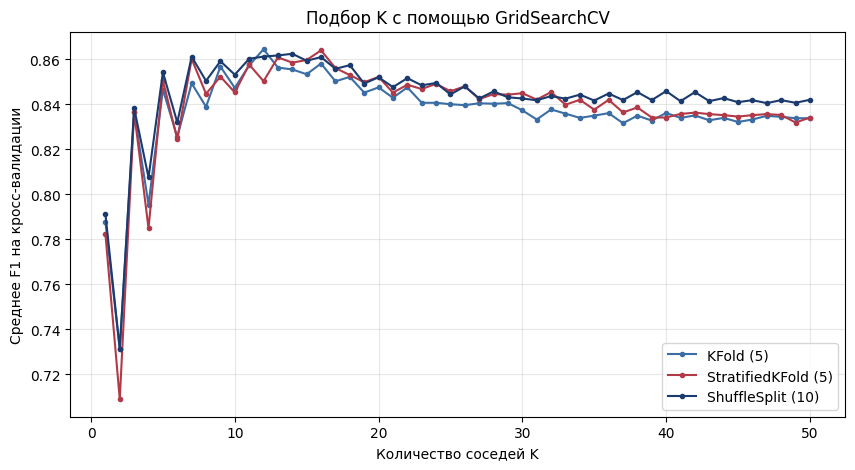

In [12]:
plt.figure(figsize=(10, 5))
colors = [BLUE, RED, BLUE_DARK]
for (name, gs), c in zip(grid_results.items(), colors):
    plt.plot(k_range, gs.cv_results_["mean_test_score"], marker="o", markersize=3, color=c, label=name)
plt.xlabel("Количество соседей K")
plt.ylabel("Среднее F1 на кросс-валидации")
plt.title("Подбор K с помощью GridSearchCV")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 6.3. RandomizedSearchCV

RandomizedSearchCV проверяет не все значения K, а случайно выбранные (здесь 15 из 50), поэтому работает быстрее.


In [13]:
rand_results = {}
for name, cv in cv_strategies.items():
    rs = RandomizedSearchCV(KNeighborsClassifier(), params, n_iter=15, cv=cv, scoring="f1", random_state=1)
    rs.fit(X_train_sc, y_train)
    rand_results[name] = rs
    print(f"{name:20} лучшее K = {rs.best_params_['n_neighbors']:2}, F1 на кросс-валидации = {rs.best_score_:.4f}")
    print(" " * 21, "проверенные K:", sorted(rs.cv_results_["param_n_neighbors"].data.tolist()))


KFold (5)            лучшее K = 22, F1 на кросс-валидации = 0.8475
                      проверенные K: [3, 4, 20, 22, 28, 30, 32, 33, 36, 37, 39, 40, 41, 47, 49]
StratifiedKFold (5)  лучшее K = 20, F1 на кросс-валидации = 0.8522
                      проверенные K: [3, 4, 20, 22, 28, 30, 32, 33, 36, 37, 39, 40, 41, 47, 49]


ShuffleSplit (10)    лучшее K = 20, F1 на кросс-валидации = 0.8520
                      проверенные K: [3, 4, 20, 22, 28, 30, 32, 33, 36, 37, 39, 40, 41, 47, 49]


### 6.4. Оценка оптимальной модели

Берём лучшее K, найденное GridSearchCV со стратифицированной кросс-валидацией (она сохраняет пропорции классов в каждом фолде), и оцениваем модель на тестовой выборке.


In [14]:
best_k = grid_results["StratifiedKFold (5)"].best_params_["n_neighbors"]
print("Оптимальное K =", best_k)

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_sc, y_train)

pred_best = knn_best.predict(X_test_sc)
proba_best = knn_best.predict_proba(X_test_sc)[:, 1]

print(f"KNN, K = {best_k}, тестовая выборка:")
metrics_best = print_metrics(y_test, pred_best, proba_best)


Оптимальное K = 16
KNN, K = 16, тестовая выборка:
Accuracy   0.7987
Precision  0.7737
Recall     1.0000
F1         0.8724
ROC-AUC    0.7254


## 7. Сравнение исходной и оптимальной моделей


In [15]:
compare = pd.DataFrame({"K = 3": metrics_3, f"K = {best_k} (оптимальное)": metrics_best}).round(4)
compare["Разница"] = (compare.iloc[:, 1] - compare.iloc[:, 0]).round(4)
compare


,K = 3,K = 16 (оптимальное),Разница
Accuracy,0.7662,0.7987,0.0325
Precision,0.7869,0.7737,-0.0132
Recall,0.9057,1.0000,0.0943
F1,0.8421,0.8724,0.0303
ROC-AUC,0.7074,0.7254,0.0180


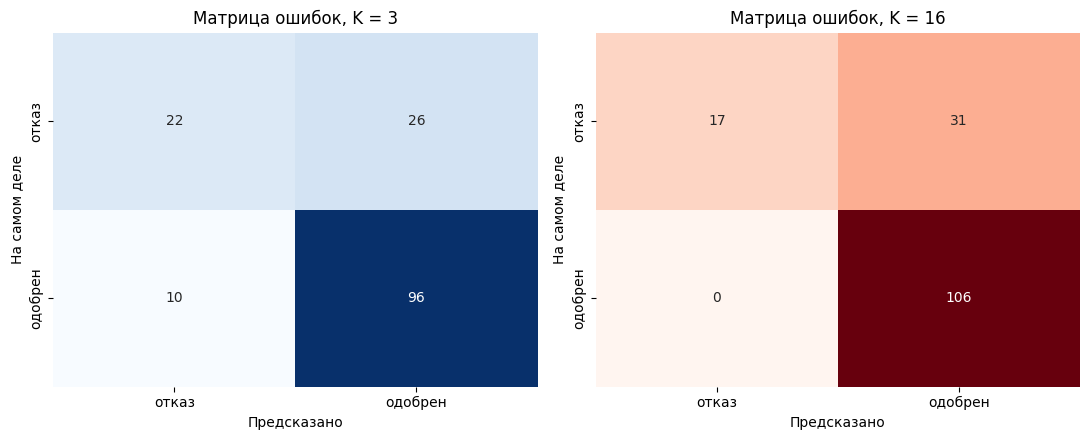

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title, cmap in [(axes[0], pred_3, "K = 3", "Blues"),
                              (axes[1], pred_best, f"K = {best_k}", "Reds")]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax,
                xticklabels=["отказ", "одобрен"], yticklabels=["отказ", "одобрен"])
    ax.set_title("Матрица ошибок, " + title)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("На самом деле")
plt.tight_layout()
plt.show()


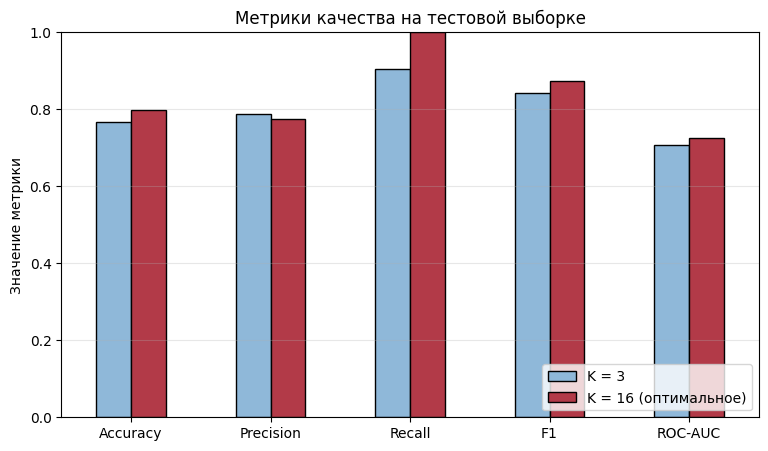

In [17]:
ax = compare.iloc[:, :2].plot(kind="bar", figsize=(9, 5), color=[BLUE_LIGHT, RED], edgecolor="black")
plt.title("Метрики качества на тестовой выборке")
plt.ylabel("Значение метрики")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()


## 8. Выводы

1. Для задачи бинарной классификации выбран финансовый датасет заявок на кредит (614 записей). Пропуски заполнены медианой и модой, категориальные признаки закодированы, признаки отмасштабированы StandardScaler (scaler обучен только на обучающей выборке).
2. Выборка разделена методом train_test_split в соотношении 75/25 со стратификацией: доля одобренных заявок в обучающей и тестовой выборках одинаковая (≈ 0,69).
3. Модель KNN с произвольным K = 3 на тестовой выборке дала accuracy 0,766, F1 0,842, ROC-AUC 0,707. Модель плохо распознаёт отказы: recall класса «отказ» всего 0,46.
4. Подбор K выполнен с помощью GridSearchCV и RandomizedSearchCV с тремя стратегиями кросс-валидации (KFold, StratifiedKFold, ShuffleSplit). GridSearchCV нашёл K = 12–16 (F1 ≈ 0,86), RandomizedSearchCV — K = 20–22: он проверил только 15 случайных значений, и диапазон 12–16 в них не попал.
5. Оптимальная модель (K = 16) на тестовой выборке лучше исходной: accuracy выросла с 0,766 до 0,799, F1 — с 0,842 до 0,872, ROC-AUC — с 0,707 до 0,725. Но по матрице ошибок видно, что модель с K = 16 чаще одобряет кредит: отказов она распознаёт меньше (17 из 48 против 22 при K = 3). При малом K модель переобучается на шум, при большом K предсказание сглаживается, поэтому подбор гиперпараметра с кросс-валидацией повышает качество.
